In [1]:

!pip install torch torchvision matplotlib numpy


In [2]:

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np

print("All libraries imported successfully!")
print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())


All libraries imported successfully!
PyTorch version: 2.11.0+cpu
GPU available: False


In [3]:

import torch
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

# Convert images into tensors and normalize them
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

# Load MNIST training dataset
dataset = torchvision.datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

print("Dataset loaded successfully!")
print("Total training images:", len(dataset))
print("Image shape:", dataset[0][0].shape)


100%|██████████| 9.91M/9.91M [00:00<00:00, 33.3MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 912kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 8.79MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.92MB/s]


Dataset loaded successfully!
Total training images: 60000
Image shape: torch.Size([1, 28, 28])


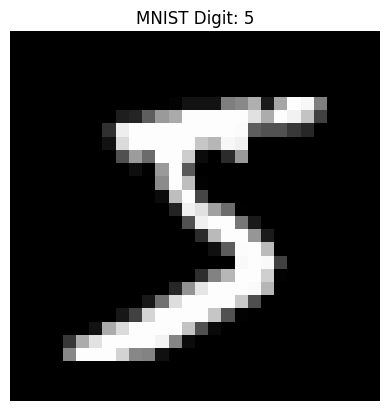

In [4]:

image, label = dataset[0]

# Convert image values from [-1, 1] to [0, 1]
image = (image + 1) / 2

plt.imshow(image.squeeze(), cmap="gray")
plt.title(f"MNIST Digit: {label}")
plt.axis("off")
plt.show()


In [5]:

from torch.utils.data import DataLoader

# Batch size
batch_size = 128

# Create DataLoader
dataloader = DataLoader(
    dataset,
    batch_size=batch_size,
    shuffle=True,
    drop_last=True
)

# Check one batch
images, labels = next(iter(dataloader))

print("DataLoader created successfully!")
print("Batch image shape:", images.shape)
print("Batch label shape:", labels.shape)


DataLoader created successfully!
Batch image shape: torch.Size([128, 1, 28, 28])
Batch label shape: torch.Size([128])


In [6]:

import torch
import torch.nn as nn

# Dimension of random noise
latent_dim = 100

# Generator network
class Generator(nn.Module):
    def __init__(self):
        super().__init__()

        self.model = nn.Sequential(
            nn.Linear(latent_dim, 128 * 7 * 7),
            nn.BatchNorm1d(128 * 7 * 7),
            nn.ReLU(True),

            nn.Unflatten(1, (128, 7, 7)),

            nn.ConvTranspose2d(
                128, 64, kernel_size=4,
                stride=2, padding=1
            ),
            nn.BatchNorm2d(64),
            nn.ReLU(True),

            nn.ConvTranspose2d(
                64, 1, kernel_size=4,
                stride=2, padding=1
            ),
            nn.Tanh()
        )

    def forward(self, z):
        return self.model(z)

# Create Generator
G = Generator()

print("Generator created successfully!")


Generator created successfully!


In [8]:
# Put the Generator in evaluation mode
G.eval()

# Generate random noise
noise = torch.randn(1, latent_dim)

# Generate one image without calculating gradients
with torch.no_grad():
    fake_image = G(noise)

print("Input noise shape:", noise.shape)
print("Generated image shape:", fake_image.shape)

Input noise shape: torch.Size([1, 100])
Generated image shape: torch.Size([1, 1, 28, 28])


In [9]:

import torch
import torch.nn as nn

# Discriminator Network
class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()

        self.model = nn.Sequential(
            nn.Conv2d(
                1, 64, kernel_size=4,
                stride=2, padding=1
            ),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(
                64, 128, kernel_size=4,
                stride=2, padding=1
            ),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Flatten(),
            nn.Linear(128 * 7 * 7, 1)
        )

    def forward(self, images):
        return self.model(images)

# Create Discriminator
D = Discriminator()

print("Discriminator created successfully!")


Discriminator created successfully!


In [10]:

# Test using a real MNIST batch
images, labels = next(iter(dataloader))

# Check one image
output = D(images[:1])

print("Input image shape:", images[:1].shape)
print("Discriminator output shape:", output.shape)
print("Discriminator score:", output.item())


Input image shape: torch.Size([1, 1, 28, 28])
Discriminator output shape: torch.Size([1, 1])
Discriminator score: -0.048133037984371185


In [11]:

import torch
import torch.nn as nn
import torch.optim as optim

# Training configuration
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

latent_dim = 100
learning_rate = 0.0002

# Move both networks to the selected device
G = G.to(device)
D = D.to(device)

# Loss function
criterion = nn.BCEWithLogitsLoss()

# Optimizer for Generator
optimizer_G = optim.Adam(
    G.parameters(),
    lr=learning_rate,
    betas=(0.5, 0.999)
)

# Optimizer for Discriminator
optimizer_D = optim.Adam(
    D.parameters(),
    lr=learning_rate,
    betas=(0.5, 0.999)
)

print("Loss function and optimizers initialized!")
print("Device:", device)


Loss function and optimizers initialized!
Device: cpu


In [13]:

# Step 8: Train the DCGAN

epochs = 5
G_losses = []
D_losses = []

for epoch in range(epochs):
    total_G_loss = 0.0
    total_D_loss = 0.0

    for real_images, _ in dataloader:
        real_images = real_images.to(device)
        current_batch = real_images.size(0)

        # Labels for real and fake images
        real_labels = torch.ones(current_batch, 1, device=device)
        fake_labels = torch.zeros(current_batch, 1, device=device)

        # -------------------------
        # Train Discriminator
        # -------------------------
        optimizer_D.zero_grad()

        real_output = D(real_images)
        real_loss = criterion(real_output, real_labels)

        noise = torch.randn(current_batch, latent_dim, device=device)
        fake_images = G(noise)

        fake_output = D(fake_images.detach())
        fake_loss = criterion(fake_output, fake_labels)

        d_loss = real_loss + fake_loss
        d_loss.backward()
        optimizer_D.step()

        # -------------------------
        # Train Generator
        # -------------------------
        optimizer_G.zero_grad()

        generated_output = D(fake_images)
        g_loss = criterion(generated_output, real_labels)

        g_loss.backward()
        optimizer_G.step()

        total_G_loss += g_loss.item()
        total_D_loss += d_loss.item()

    avg_G_loss = total_G_loss / len(dataloader)
    avg_D_loss = total_D_loss / len(dataloader)

    G_losses.append(avg_G_loss)
    D_losses.append(avg_D_loss)

    print(
        f"Epoch [{epoch + 1}/{epochs}] "
        f"Generator Loss: {avg_G_loss:.4f}, "
        f"Discriminator Loss: {avg_D_loss:.4f}"
    )

print("Training completed!")


Epoch [1/5] Generator Loss: 2.4443, Discriminator Loss: 0.3512
Epoch [2/5] Generator Loss: 2.8116, Discriminator Loss: 0.2628
Epoch [3/5] Generator Loss: 3.0042, Discriminator Loss: 0.2406
Epoch [4/5] Generator Loss: 2.9571, Discriminator Loss: 0.2638
Epoch [5/5] Generator Loss: 2.8244, Discriminator Loss: 0.3229
Training completed!


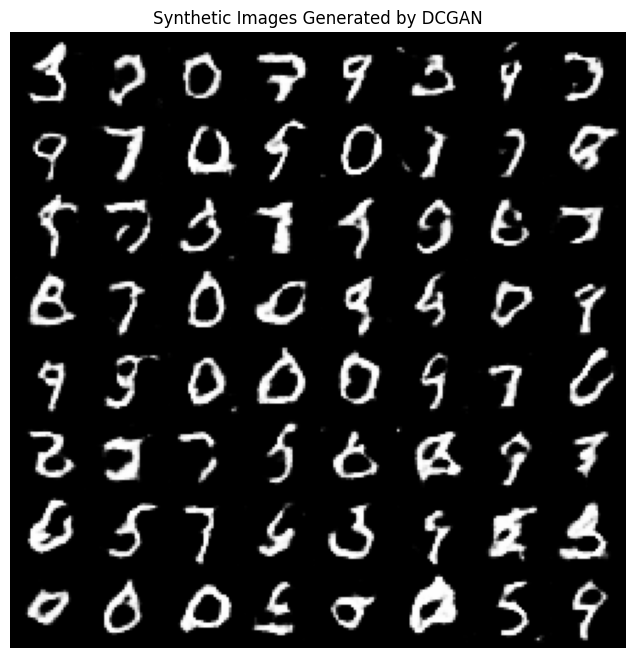

Generated images saved!


<Figure size 640x480 with 0 Axes>

In [14]:

from torchvision.utils import make_grid
import matplotlib.pyplot as plt
import torch

# Generate 64 images
G.eval()

fixed_noise = torch.randn(64, latent_dim, device=device)

with torch.no_grad():
    generated_images = G(fixed_noise).cpu()

# Convert pixel range from [-1, 1] to [0, 1]
generated_images = (generated_images + 1) / 2

# Display images in a grid
grid = make_grid(generated_images, nrow=8)

plt.figure(figsize=(8, 8))
plt.imshow(grid.permute(1, 2, 0).squeeze(), cmap="gray")
plt.title("Synthetic Images Generated by DCGAN")
plt.axis("off")
plt.show()

# Save the generated image grid
plt.savefig("generated_images.png")
print("Generated images saved!")


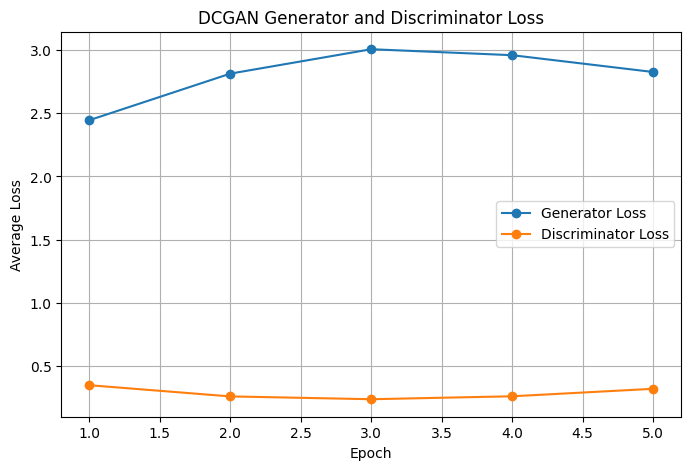

Loss graph saved!


<Figure size 640x480 with 0 Axes>

In [15]:

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(G_losses) + 1),
    G_losses,
    marker="o",
    label="Generator Loss"
)

plt.plot(
    range(1, len(D_losses) + 1),
    D_losses,
    marker="o",
    label="Discriminator Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Average Loss")
plt.title("DCGAN Generator and Discriminator Loss")
plt.legend()
plt.grid(True)
plt.show()

plt.savefig("loss_curves.png")
print("Loss graph saved!")
